# Figure 1

Redraws every data panel of Figure 1 from the source data workbook `Figure_1.xlsx`. The schematic card on the right of panel a has no data and is not redrawn; the grey intercity spending ties drawn as background texture on the national map are not released (city-pair data) and are not redrawn.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager

SOURCE = Path("..") / "Source data"                     # relative to this notebook's folder
BOOK = SOURCE / "Figure_1.xlsx"
# Boundary files are not redistributed; point GIS to a local copy (here the Dataset folder next to the repository).
GIS = Path("..") / ".." / "Dataset" / "GIS"
CITIES_SHP = GIS / "Prefecture City.shp"
BORDER_SHP = GIS / "guojie.shp"

FONT = "Calibri" if any(f.name == "Calibri" for f in font_manager.fontManager.ttflist) else "Carlito"
BASE, LETTER = 7.5, 10.5                                        # all text 7.5 pt; panel letters 10.5 pt bold
MM = 1 / 25.4
WIDTH = 180 * MM                                                # width of the published figure (in)
INK, INK3, GRIDC, NAVY = "#0b0b0b", "#76756f", "#eeeeec", "#22314a"
COL = {"local": "#2f6db5", "inbound": "#1a9e6f", "outbound": "#e86a33"}
TEAL, CORAL, GREY, LAND, EDGE = "#1795a3", "#d9644f", "#c7c6c1", "#f4f3f0", "#ffffff"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT], "mathtext.fontset": "custom",
    "mathtext.rm": FONT, "mathtext.it": f"{FONT}:italic", "mathtext.bf": f"{FONT}:bold",
    "mathtext.cal": FONT, "mathtext.sf": FONT, "mathtext.tt": FONT,
    "font.size": BASE, "axes.labelsize": BASE, "xtick.labelsize": BASE, "ytick.labelsize": BASE,
    "legend.fontsize": BASE, "axes.titlesize": BASE, "legend.title_fontsize": BASE, "legend.labelcolor": INK,
    "text.color": INK, "axes.edgecolor": INK3, "axes.linewidth": 0.5, "xtick.color": INK3, "ytick.color": INK3,
    "xtick.labelcolor": INK, "ytick.labelcolor": INK, "axes.labelcolor": INK,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2,
    "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
    "legend.frameon": False, "axes.unicode_minus": True,
    "figure.dpi": 300, "figure.facecolor": "white", "figure.edgecolor": "white", "savefig.facecolor": "white"})
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}


def panel_figure(x0, y0, w, h):
    """One panel as a standalone figure; positions are inches from the lower-left corner of the published figure."""
    fig = plt.figure(figsize=(w, h))

    def ax_in(x, y, ww, hh, **kw):
        return fig.add_axes([(x - x0) / w, (y - y0) / h, ww / w, hh / h], **kw)

    def letter(x, y, s):
        fig.text((x - x0) / w, (y - y0) / h, s, fontsize=LETTER, fontweight="bold", color=INK, va="top", ha="left")

    def T(x, y, s, **kw):
        kw.setdefault("fontsize", BASE)
        kw.setdefault("color", INK)
        return fig.text((x - x0) / w, (y - y0) / h, s, **kw)

    return fig, ax_in, letter, T


def overlay(ax_in, x0, y0, w, h):
    """Transparent axes covering the panel, with data coordinates in inches of the published figure."""
    ov = ax_in(x0, y0, w, h)
    ov.set_xlim(x0, x0 + w)
    ov.set_ylim(y0, y0 + h)
    ov.axis("off")
    ov.patch.set_alpha(0)
    return ov


def clean(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if grid:
        ax.grid(axis=grid, color=GRIDC, lw=0.5)
        ax.set_axisbelow(True)


def nfmt(v, nd=1):
    return f"{v:.{nd}f}".replace("-", "\u2212")


def mfmt(v, nd=1):
    return f"{v:+.{nd}f}".replace("-", "\u2212")


def pfmt(p):
    return r"$P$ < 0.001" if p < 0.001 else rf"$P$ = {p:.3f}" if p < 0.01 else rf"$P$ = {p:.2f}"

import geopandas as gpd
from pyproj import Transformer
from shapely.geometry import Point

CRS = "epsg:4793"
CUT = 1.95e6


def read_boundaries(simplify):
    """Prefecture polygons (projected, simplified) and the national border without the South China Sea dash set."""
    cities = gpd.read_file(CITIES_SHP).to_crs(CRS)
    cities["city_name"] = cities.city_name.str.strip()
    full = cities.copy()
    cities["geometry"] = cities.geometry.simplify(simplify)
    border = gpd.read_file(BORDER_SHP).to_crs(CRS)
    main = border[border.bounds["maxy"] >= CUT].copy()
    length = main.length
    chord = main.geometry.apply(lambda g: Point(g.coords[0]).distance(Point(g.coords[-1])))
    cen = main.geometry.centroid
    lat = np.asarray(Transformer.from_crs(CRS, "epsg:4326", always_xy=True).transform(cen.x.to_numpy(),
                                                                                      cen.y.to_numpy())[1])
    dash = (chord / length > 0.97) & length.between(100e3, 150e3) & (lat < 26)
    return cities, full, border, main.loc[~dash]


def south_china_sea_inset(ins, border):
    border.plot(ax=ins, color=INK3, linewidth=0.3)
    ins.set_xlim(0.10e6, 2.15e6)
    ins.set_ylim(0.0, 2.65e6)
    ins.set_aspect("equal")
    ins.set_xticks([])
    ins.set_yticks([])
    ins.set_xlabel("")
    ins.set_ylabel("")
    for s in ins.spines.values():
        s.set_linewidth(0.4)
        s.set_color(INK3)

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea
from matplotlib.patches import Rectangle
from pyproj import Geod

H = 5.116                                                       # height of the published figure (in)
FOOT = "#eed39d"                                                # rainfall-system footprint fill
FOOT_EDGE, FOOT_EDGE_ZOOM = "#8a5a1c", "#c1862f"
EV_COL = ["#d9d7d1", "#f0d9a4", "#dfb262", "#c1862f", "#8a5a1c"]   # events per city: 0, 1, 2, 3-4, >=5
EV_LAB = ["0", "1", "2", "3–4", "≥5"]
EV_DOT = 12
NAME = {"local": "Local", "inbound": "Inbound", "outbound": "Outbound"}
HALO = [pe.withStroke(linewidth=2.0, foreground="white")]
MAIN_X, MAIN_Y = (-2.62e6, 2.80e6), (1.25e6, 6.15e6)
ZOOM_W, ZOOM_N, ZOOM_S = 490e3, 549e3, 480e3                    # zoom window (m from the focal city)
EXT_LABELS = ["1", "2–5", "6–15", ">15"]


def ci(v, lo, hi, nd=2):
    f = lambda x: f"{x:.{nd}f}".replace("-", "\u2212")
    return f"{f(v)} [{f(lo)}, {f(hi)}]"


def footprint_outline(units):
    """Outer outline of the footprint units (slivers closed, inner rings dropped)."""
    merged = units.geometry.union_all().buffer(2500).buffer(-2500)
    parts = list(merged.geoms) if hasattr(merged, "geoms") else [merged]
    return gpd.GeoSeries([p.exterior for p in parts], crs=units.crs)


def bezier(p, f, bend=0.16, n=30):
    p, f = np.asarray(p, float), np.asarray(f, float)
    c = (p + f) / 2 + bend * np.array([-(f - p)[1], (f - p)[0]])
    t = np.linspace(0, 1, n)[:, None]
    return (1 - t) ** 2 * p + 2 * (1 - t) * t * c + t ** 2 * f


def halo_text(ax, x, y, s, **kw):
    z = kw.pop("zorder", 9)
    ax.text(x, y, s, fontsize=BASE, color="white", zorder=z - 0.1, path_effects=HALO, **kw)
    return ax.text(x, y, s, fontsize=BASE, color=INK, zorder=z, **kw)

**Panel a** (maps): sample cities by number of events, the footprint of one rainfall system and the focal city's partners.

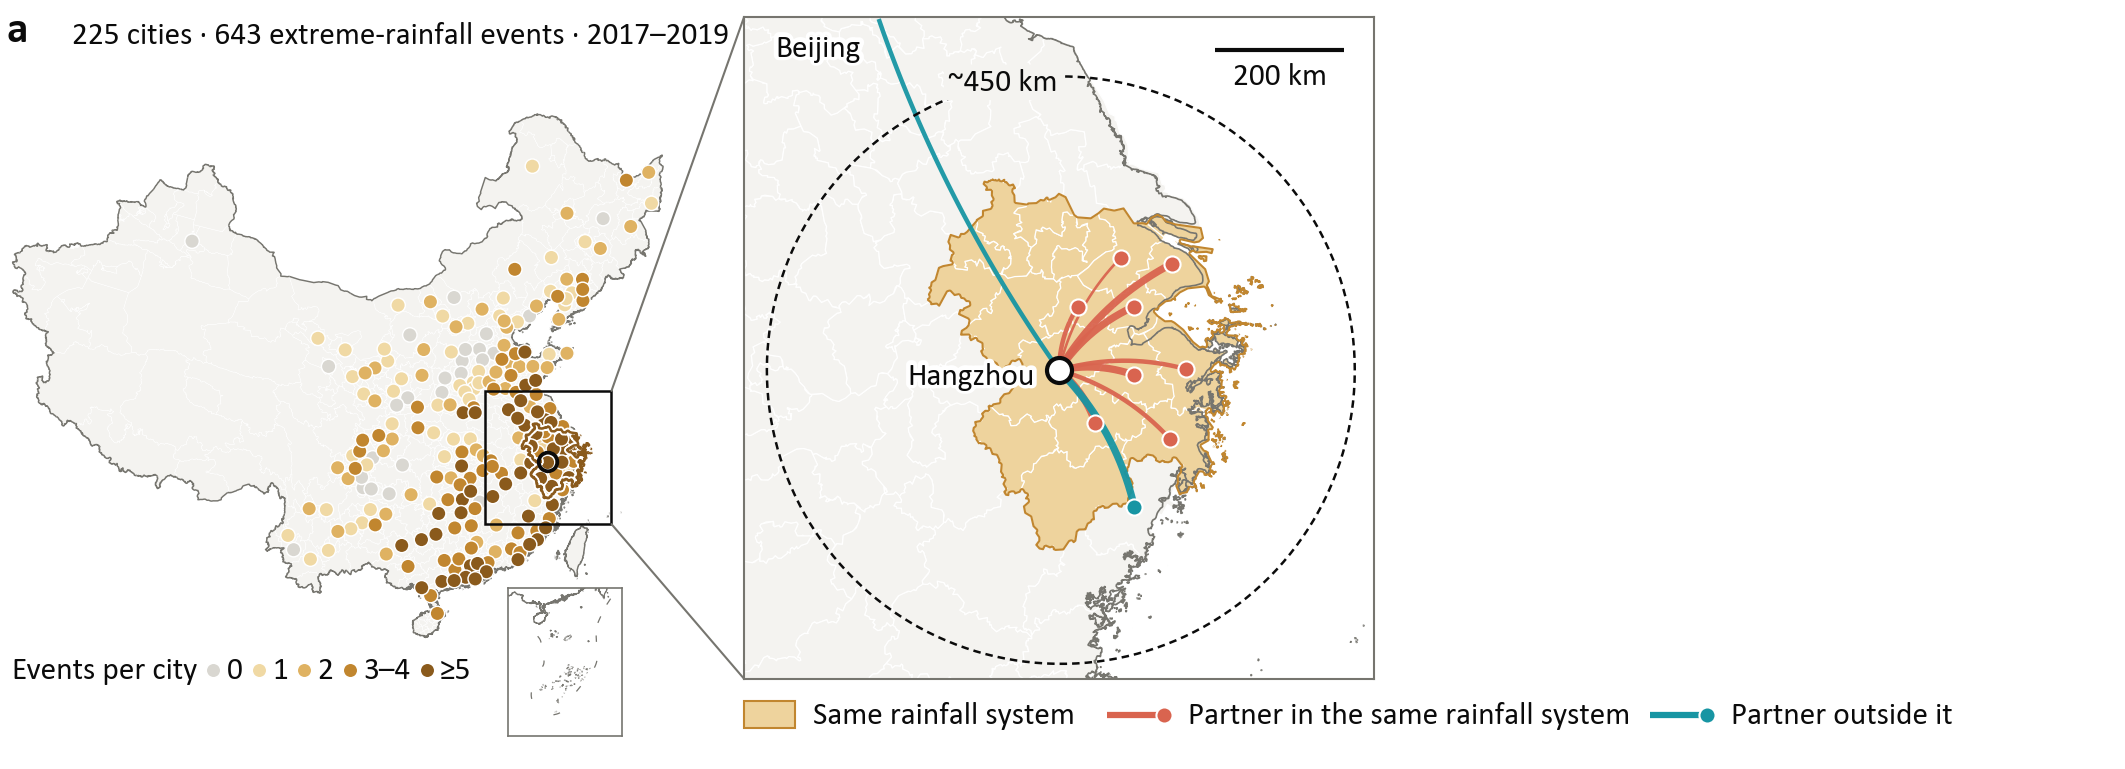

In [2]:
cty = pd.read_excel(BOOK, sheet_name="Fig1a_cities")
fpt = pd.read_excel(BOOK, sheet_name="Fig1a_footprint")
prt = pd.read_excel(BOOK, sheet_name="Fig1a_partners")
summary = pd.read_excel(BOOK, sheet_name="Fig1a_summary").set_index("item")["value"]

X0, Y0, PW, PH = 0.0, 2.55, WIDTH, H - 2.55
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
ov = overlay(ax_in, X0, Y0, PW, PH)
ov.set_zorder(20)
TOP = H - 0.04
letter(0.02, TOP, "a")
cities, full, border, border_main = read_boundaries(1500)
tr = Transformer.from_crs("EPSG:4326", CRS, always_xy=True)
focal = prt.loc[prt.role == "focal"].iloc[0]
partners = prt.loc[prt.role == "partner"]
hx, hy = tr.transform(focal.lon, focal.lat)
foot = set(fpt.city_name)

# national map
NX0, NW = 0.0, 2.34
NH = NW * (MAIN_Y[1] - MAIN_Y[0]) / (MAIN_X[1] - MAIN_X[0])
NY0 = TOP - 0.30 - NH
axn = ax_in(NX0, NY0, NW, NH)
cities.plot(ax=axn, facecolor=LAND, edgecolor=EDGE, linewidth=0.12, zorder=1)
cities.loc[cities.city_name.isin(foot)].plot(ax=axn, facecolor=FOOT, edgecolor=EDGE, linewidth=0.12, zorder=1.5)
border_main.plot(ax=axn, color=INK3, linewidth=0.35, zorder=2)
outline = footprint_outline(cities.loc[cities.city_name.isin(foot)])
outline.plot(ax=axn, color="white", linewidth=1.5, zorder=4.9)
outline.plot(ax=axn, color=FOOT_EDGE, linewidth=0.6, zorder=5)
mp = cty.loc[cty.mapped == 1]
cls = mp.events_class.to_numpy()
order = np.argsort(cls, kind="stable")                         # cities with more events drawn on top
mx, my = tr.transform(mp.lon.to_numpy(), mp.lat.to_numpy())
axn.scatter(np.asarray(mx)[order], np.asarray(my)[order], s=EV_DOT, c=[EV_COL[i] for i in cls[order]],
            edgecolor="white", linewidths=0.35, zorder=3)
axn.scatter([hx], [hy], s=20, facecolor="none", edgecolor=INK, lw=0.9, zorder=6)
axn.add_patch(Rectangle((hx - ZOOM_W, hy - ZOOM_S), 2 * ZOOM_W, ZOOM_S + ZOOM_N, facecolor="none", edgecolor=INK,
                        lw=0.6, zorder=7))
axn.set_xlim(*MAIN_X)
axn.set_ylim(*MAIN_Y)
axn.set_aspect("equal")
axn.axis("off")
n_scale = (MAIN_X[1] - MAIN_X[0]) / NW
NPX = lambda X, Y: (NX0 + (X - MAIN_X[0]) / n_scale, NY0 + (Y - MAIN_Y[0]) / n_scale)
south_china_sea_inset(ax_in(NPX(1.30e6, 0)[0], NY0, 0.38, 0.38 * 2.65e6 / 2.05e6), border)
ov.text(0.24, TOP - 0.035, f"{int(summary['sample cities'])} cities · "
        f"{int(summary['analysed extreme-rainfall events'])} extreme-rainfall events · 2017–2019",
        fontsize=BASE, color=INK, ha="left", va="top")
yy = NY0 + 0.22
ov.text(0.04, yy, "Events per city", fontsize=BASE, color=INK, ha="left", va="center")
xx = 0.71
for col_, lab_ in zip(EV_COL, EV_LAB):
    ov.scatter([xx], [yy], s=EV_DOT, color=col_, edgecolor="white", linewidths=0.35)
    ov.text(xx + 0.045, yy, lab_, fontsize=BASE, color=INK, ha="left", va="center")
    xx += 0.10 + 0.052 * len(lab_)

# zoom map
ZX0, ZW = 2.48, 2.10
ZH = ZW * (ZOOM_S + ZOOM_N) / (2 * ZOOM_W)
ZY0 = TOP - 0.02 - ZH
axz = ax_in(ZX0, ZY0, ZW, ZH)
x0, x1, y0, y1 = hx - ZOOM_W, hx + ZOOM_W, hy - ZOOM_S, hy + ZOOM_N
mpi = 2 * ZOOM_W / ZW                                           # metres per inch
win = cities.cx[x0 - 5e4:x1 + 5e4, y0 - 5e4:y1 + 5e4]
win.plot(ax=axz, facecolor=LAND, edgecolor=EDGE, linewidth=0.3, zorder=1)
win.loc[win.city_name.isin(foot)].plot(ax=axz, facecolor=FOOT, edgecolor=EDGE, linewidth=0.3, zorder=1.5)
footprint_outline(win.loc[win.city_name.isin(foot)]).plot(ax=axz, color=FOOT_EDGE_ZOOM, linewidth=0.5, zorder=2.2)
border_main.cx[x0 - 5e4:x1 + 5e4, y0 - 5e4:y1 + 5e4].plot(ax=axz, color=INK3, linewidth=0.4, zorder=2)
radius_m = 1e3 * float(summary["reference circle radius around the focal city (km)"])
lon, lat = np.array(Geod(ellps="WGS84").fwd(np.full(361, focal.lon), np.full(361, focal.lat),
                                            np.linspace(0, 360, 361), np.full(361, radius_m))[:2])
ccx, ccy = (np.asarray(v) for v in tr.transform(lon, lat))
axz.plot(ccx, ccy, color=INK, lw=0.6, ls=(0, (3, 2)), zorder=5)
edge = []
for p in partners.itertuples():                                 # heavier weight classes drawn last
    px, py = tr.transform(p.lon, p.lat)
    col = CORAL if p.same_system == 1 else TEAL
    inside = (x0 < px < x1) and (y0 < py < y1)
    curve = bezier((hx, hy), (px, py), 0.14, 200)
    if not inside:                                              # run the tie to the frame edge
        ok = (curve[:, 0] > x0) & (curve[:, 0] < x1) & (curve[:, 1] > y0) & (curve[:, 1] < y1)
        curve = curve[:int(np.argmin(ok))]
        px, py = curve[-1]
        edge.append((p.name_en, px, py))
    axz.plot(curve[:, 0], curve[:, 1], color=col, lw=p.line_width_pt, solid_capstyle="butt", zorder=4, alpha=0.95)
    if inside:
        axz.scatter([px], [py], s=15, color=col, edgecolor="white", linewidths=0.5, zorder=6)
axz.scatter([hx], [hy], s=36, facecolor="white", edgecolor=INK, lw=1.0, zorder=7)
halo_text(axz, hx - 0.08 * mpi, hy - 0.02 * mpi, focal.name_en, ha="right", va="center")
for name, ex, ey in edge:
    halo_text(axz, ex - 0.06 * mpi, ey - 0.05 * mpi, name, ha="right", va="top")
axz.text(ccx[355], ccy[355], f"~{radius_m / 1e3:.0f} km", fontsize=BASE, color=INK, ha="center", va="center", zorder=9,
         bbox=dict(boxstyle="round,pad=0.12,rounding_size=0.08", facecolor=LAND, edgecolor="none"))
sx1, sy = x1 - 0.10 * mpi, y1 - 0.11 * mpi                      # 200 km scale bar
axz.plot([sx1 - 200e3, sx1], [sy, sy], color=INK, lw=1.0, solid_capstyle="butt", zorder=9)
halo_text(axz, sx1 - 100e3, sy - 0.04 * mpi, "200 km", ha="center", va="top")
axz.set_xlim(x0, x1)
axz.set_ylim(y0, y1)
axz.set_aspect("equal")
axz.set_xticks([])
axz.set_yticks([])
axz.set_xlabel("")
axz.set_ylabel("")
for s in axz.spines.values():
    s.set_visible(True)
    s.set_linewidth(0.5)
    s.set_color(INK3)
    s.set_zorder(10)
for (X, Y), (zx, zy) in (((hx + ZOOM_W, hy + ZOOM_N), (ZX0, ZY0 + ZH)), ((hx + ZOOM_W, hy - ZOOM_S), (ZX0, ZY0))):
    ov.plot([NPX(X, Y)[0], zx], [NPX(X, Y)[1], zy], color=INK3, lw=0.5, solid_capstyle="round", zorder=1)
yk, xk = NY0 + 0.07, ZX0
ov.add_patch(Rectangle((xk, yk - 0.045), 0.17, 0.09, facecolor=FOOT, edgecolor=FOOT_EDGE_ZOOM, lw=0.5))
ov.text(xk + 0.23, yk, "Same rainfall system", fontsize=BASE, color=INK, ha="left", va="center")
xk += 0.23 + 0.82 + 0.16
for col_, lab_, w_ in ((CORAL, "Partner in the same rainfall system", 1.38), (TEAL, "Partner outside it", 0.67)):
    ov.plot([xk, xk + 0.19], [yk, yk], color=col_, lw=1.5, solid_capstyle="butt")
    ov.scatter([xk + 0.19], [yk], s=15, color=col_, edgecolor="white", linewidths=0.5, zorder=3)
    ov.text(xk + 0.27, yk, lab_, fontsize=BASE, color=INK, ha="left", va="center")
    xk += 0.27 + w_ + 0.16
plt.show()

**Panel b**: change from the pre-event baseline by day from rainfall onset, local, inbound and outbound spending.

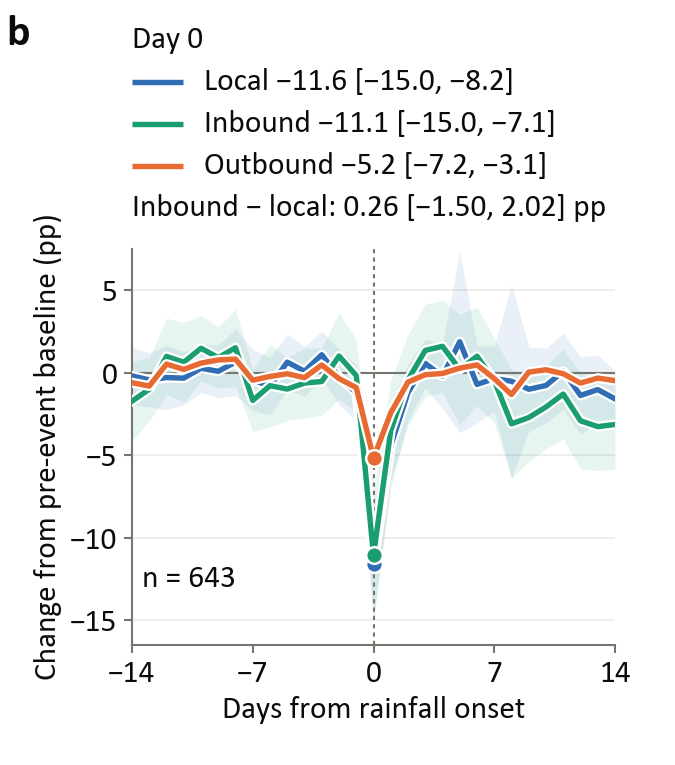

In [3]:
et = pd.read_excel(BOOK, sheet_name="Fig1b")
bsum = pd.read_excel(BOOK, sheet_name="Fig1b_summary")

X0, Y0, PW, PH = 0.0, 0.0, 2.25, 2.55
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
ov = overlay(ax_in, X0, Y0, PW, PH)
ov.set_zorder(20)
R2, BXA, BWA = 2.50, 0.44, 1.61
axb = ax_in(BXA, 0.40, BWA, 1.32)
clean(axb)
letter(0.02, R2, "b")
t0 = et.loc[et.days_from_onset == 0].set_index("margin")
ZB = {"local": 3.0, "inbound": 3.2, "outbound": 3.6}
for k in ("outbound", "inbound", "local"):
    q = et.loc[et.margin == k].sort_values("days_from_onset")
    if k != "outbound":
        axb.fill_between(q.days_from_onset, q.ci_low_pp, q.ci_high_pp, color=COL[k], alpha=0.10, lw=0, zorder=1)
    axb.plot(q.days_from_onset, q.change_pp, color=COL[k], lw=1.3, zorder=ZB[k], solid_joinstyle="round",
             path_effects=[pe.Stroke(linewidth=2.4, foreground="white"), pe.Normal()])
    axb.scatter([0], [t0.loc[k, "change_pp"]], s=16, color=COL[k], edgecolor="white", lw=0.6, zorder=ZB[k] + 1)
axb.axvline(0, color=INK3, lw=0.5, ls=(0, (2, 2)), zorder=2)
axb.axhline(0, color=INK3, lw=0.5, zorder=2)
axb.set_xlim(-14, 14)
axb.set_ylim(-16.5, 7.5)
axb.set_xticks([-14, -7, 0, 7, 14])
axb.set_yticks([-15, -10, -5, 0, 5])
axb.set_xlabel("Days from rainfall onset")
axb.set_ylabel("Change from pre-event baseline (pp)")
n_events = int(bsum.loc[bsum.item.str.startswith("events"), "estimate"].iloc[0])
axb.text(-13.4, -12.5, f"n = {n_events}", fontsize=BASE, color=INK, ha="left", va="center")
ov.text(BXA, R2 - 0.085, "Day 0", fontsize=BASE, color=INK, ha="left", va="center")
for i, k in enumerate(NAME):
    yy = R2 - 0.225 - 0.14 * i
    ov.plot([BXA, BXA + 0.17], [yy, yy], color=COL[k], lw=1.3, solid_capstyle="butt")
    ov.text(BXA + 0.24, yy, f"{NAME[k]} {ci(t0.loc[k, 'change_pp'], t0.loc[k, 'ci_low_pp'], t0.loc[k, 'ci_high_pp'], 1)}",
            fontsize=BASE, color=INK, ha="left", va="center")
g0 = bsum.loc[bsum.item.str.startswith("inbound minus local")].iloc[0]
ov.text(BXA, R2 - 0.225 - 0.14 * 3, f"Inbound − local: {ci(g0.estimate, g0.ci_low, g0.ci_high)} pp",
        fontsize=BASE, color=INK, ha="left", va="center")
plt.show()

**Panel c**: decline of inbound and outbound spending relative to local spending.

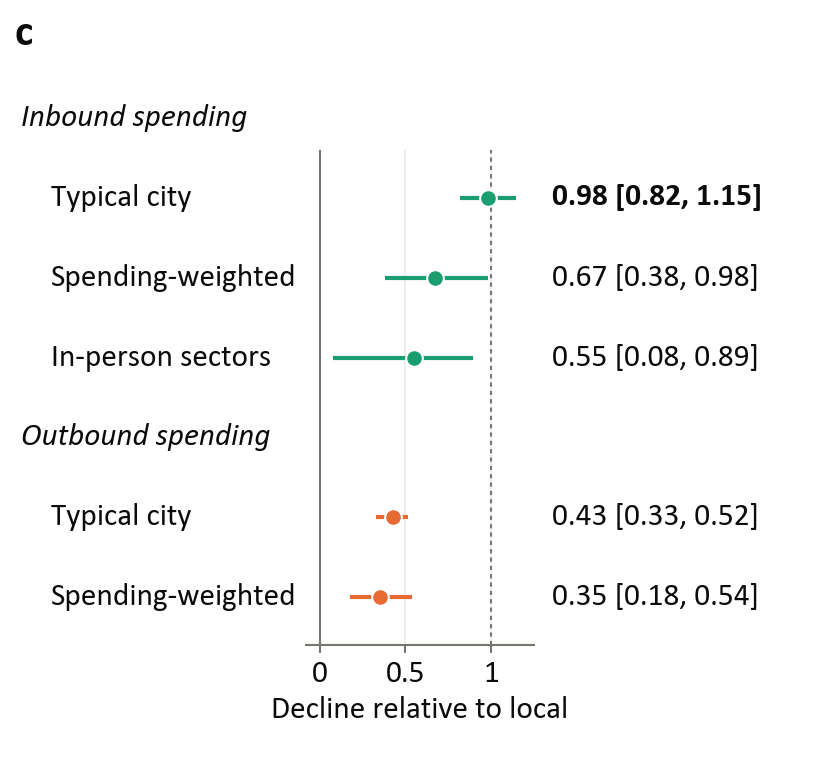

In [4]:
dr = pd.read_excel(BOOK, sheet_name="Fig1c")

X0, Y0, PW, PH = 2.25, 0.0, 2.72, 2.55
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
CL, R2 = 2.30, 2.50
letter(CL, R2, "c")
CXA, CYA, CWA, CHA = 3.27, 0.40, 0.76, 1.65
axc = ax_in(CXA, CYA, CWA, CHA)
clean(axc, grid="x")
axc.spines["left"].set_visible(False)
axc.tick_params(axis="y", left=False, labelleft=False)
ylines = [1, 2, 3, 5, 6]                                        # 0 and 4 = italic group headers
YMAX = 6.6
axc.set_ylim(YMAX, 0.4)
fy = lambda yy: CYA + CHA * (YMAX - yy) / (YMAX - 0.4)
header = None
for r, yy in zip(dr.itertuples(), ylines):
    col = COL["inbound"] if r.margin_group.startswith("Inbound") else COL["outbound"]
    axc.plot([r.ci_low, r.ci_high], [yy, yy], color=col, lw=1.0, zorder=2, solid_capstyle="butt")
    axc.scatter([r.decline_ratio], [yy], s=16, color=col, edgecolor="white", lw=0.5, zorder=3)
    T(CXA + CWA + 0.06, fy(yy), ci(r.decline_ratio, r.ci_low, r.ci_high), ha="left", va="center",
      fontweight="bold" if r.printed_bold == 1 else "normal")
    T(CL + 0.12, fy(yy), r.row_label, ha="left", va="center")
    if r.margin_group != header:
        T(CL + 0.02, fy(yy - 1), r.margin_group, ha="left", va="center", style="italic")
        header = r.margin_group
axc.set_xlim(-0.08, 1.25)
axc.set_xticks([0, 0.5, 1.0])
axc.set_xticklabels(["0", "0.5", "1"])
axc.axvline(1, color=INK3, lw=0.5, ls=(0, (2, 2)), zorder=1)
axc.axvline(0, color=INK3, lw=0.5, zorder=1)
axc.set_xlabel("Decline relative to local")
plt.show()

**Panel d**: partner demand hit (upper) and change in city spending (lower) by the number of cities hit by the same rainfall system.

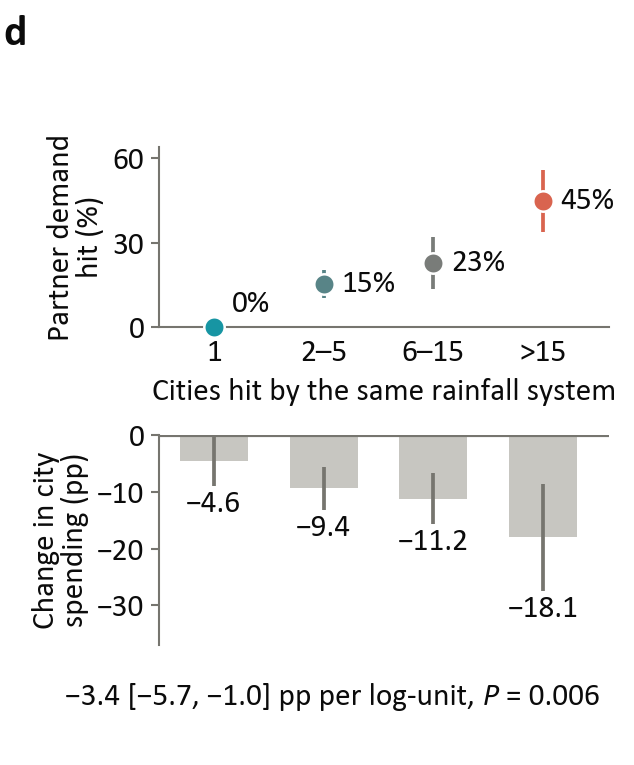

In [5]:
top = pd.read_excel(BOOK, sheet_name="Fig1d_top").set_index("cities_hit_class").loc[EXT_LABELS]
bot = pd.read_excel(BOOK, sheet_name="Fig1d_bottom").set_index("cities_hit_class").loc[EXT_LABELS]
slope = pd.read_excel(BOOK, sheet_name="Fig1d_slope")

X0, Y0, PW, PH = 4.97, 0.0, WIDTH - 4.97, 2.55
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
ov = overlay(ax_in, X0, Y0, PW, PH)
ov.set_zorder(20)
DL, R2 = 4.98, 2.50
letter(DL, R2, "d")
DX, DW = 5.50, 1.50
axt = ax_in(DX, 1.46, DW, 0.60)                                 # above the axis: partner demand hit
axd = ax_in(DX, 0.40, DW, 0.70)                                 # below the axis: change in city spending
xd = np.arange(4)
clean(axt, grid=None)
cmap = LinearSegmentedColormap.from_list("teal_coral", [TEAL, CORAL])
for i, lab in enumerate(EXT_LABELS):
    r = top.loc[lab]
    col = cmap(min(1.0, r.partner_demand_hit_pct / 45.0))
    axt.vlines(i, r.ci_low_pct, r.ci_high_pct, color=col, lw=0.9, zorder=2)
    axt.scatter([i], [r.partner_demand_hit_pct], s=24, color=col, edgecolor="white", lw=0.6, zorder=3, clip_on=False)
    axt.text(i + 0.16, max(r.partner_demand_hit_pct, 8), f"{r.partner_demand_hit_pct:.0f}%", fontsize=BASE, color=INK,
             ha="left", va="center")
axt.set_xlim(-0.5, 3.6)
axt.set_ylim(0, 64)
axt.set_yticks([0, 30, 60])
axt.set_xticks(xd)
axt.set_xticklabels(EXT_LABELS)
axt.tick_params(axis="x", length=0, pad=3)
axt.set_xlabel("Cities hit by the same rainfall system", labelpad=2.5)
axt.set_ylabel("Partner demand\nhit (%)", linespacing=1.05)
clean(axd, grid=None)
axd.spines["bottom"].set_visible(False)
axd.tick_params(axis="x", bottom=False, labelbottom=False)
axd.bar(xd, bot.change_pp, width=0.62, color=GREY, lw=0, zorder=2)
axd.vlines(xd, bot.ci_low_pp, bot.ci_high_pp, color=INK3, lw=0.9, zorder=3)
axd.axhline(0, color=INK3, lw=1.0, zorder=3)
for i, lab in enumerate(EXT_LABELS):
    r = bot.loc[lab]
    axd.text(i, r.ci_low_pp - 0.7, f"{r.change_pp:.1f}".replace("-", "\u2212"), fontsize=BASE, color=INK,
             ha="center", va="top")
axd.set_xlim(-0.5, 3.6)
axd.set_ylim(-37, 0)
axd.set_yticks([-30, -20, -10, 0])
axd.set_ylabel("Change in city\nspending (pp)", linespacing=1.05)
s1 = slope.loc[slope.drawn == 1].iloc[0]
pv = s1.p_value
runs = [(f"{ci(s1.slope_pp_per_log_unit, s1.ci_low, s1.ci_high, 1)} pp per log-unit,", "normal"), ("P", "italic"),
        ("< 0.001" if pv < 0.001 else f"= {pv:.3f}" if pv < 0.01 else f"= {pv:.2f}", "normal")]
packed = HPacker(children=[TextArea(t, textprops=dict(fontsize=BASE, color=INK, style=st)) for t, st in runs],
                 align="baseline", pad=0, sep=1.8)
ov.add_artist(AnchoredOffsetbox(loc="lower right", child=packed, pad=0, borderpad=0, frameon=False,
                                bbox_to_anchor=(DX + DW - 0.03, 0.18), bbox_transform=ov.transData))
fig.align_ylabels([axt, axd])
plt.show()